# Vehicle Type Classification: Bayes classifiers, logistic regression and decision trees

**Task.** Predict `vehicle_class` (0, 1 or 2) from 20 numeric vehicle specifications (a Kaggle-style course project).

**Models allowed (course so far):** Gaussian Naive Bayes, LDA, QDA, logistic regression (ridge / lasso) and decision trees. Nothing else is used (no random forest, boosting, SVM, KNN or neural networks).

**Protocol in one paragraph.** Exact duplicate rows are removed first (see section 1, they would leak between CV folds). Every model is a scikit-learn `Pipeline`, so scaling and feature selection are re-fitted inside each CV training fold (no leakage). All models are scored on the *same* 15 folds (5-fold stratified CV repeated 3 times), hyper-parameters are tuned only with these folds, and the unlabeled test file is touched exactly once, at the very end, for prediction.

*Tested with scikit-learn 1.9, pandas 3 and seaborn 0.13. The logistic-regression penalty argument is written to also work on scikit-learn < 1.8 (that code path was not run here, only 1.9.1 was). Expected total run time: roughly 10 to 15 minutes on 2 CPU cores.*

In [1]:
# ---------- Setup: imports, global seed, plotting style ----------
import os, time, tempfile, warnings
# Silence only known-harmless warnings (also inside joblib worker processes).
os.environ["PYTHONWARNINGS"] = "ignore::FutureWarning,ignore::UserWarning:sklearn.discriminant_analysis"
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*collinear.*")   # QDA warns about collinear features; expected here

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from joblib import Memory

import sklearn
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectFromModel, SequentialFeatureSelector, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_score, cross_val_predict, validation_curve)
from sklearn.metrics import confusion_matrix

SEED = 42                       # one seed used for every random_state in this notebook
np.random.seed(SEED)

# Plot style: light grid, no top/right spines, one colour per class (blue, orange, aqua)
CLASS_COLORS = {0: "#2a78d6", 1: "#eb6834", 2: "#1baf7a"}
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titlesize": 11, "axes.labelsize": 10,
                     "legend.frameon": False})
pd.set_option("display.max_colwidth", None, "display.width", 200, "display.max_columns", 50)
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

scikit-learn 1.9.1 | pandas 3.0.5 | numpy 2.5.3


## 1. Problem and dataset

We classify vehicles into three classes using 20 numeric specifications (engine size, power, dimensions, fuel economy, battery capacity and so on). `vehicle_id` is only a row index, so it is **removed from the features** but kept to build the submission file. The test file has no labels, so all model selection is done with cross-validation on the training file.

In [2]:
# ---------- Load data (CSV files are expected next to the notebook, or in ./data) ----------
def find_data_dir():
    for d in [Path("."), Path("data"), Path("../data"), Path("vehicle-type-classification")]:
        if (d / "vehicle_train_10000.csv").exists():
            return d
    raise FileNotFoundError("Put vehicle_train_10000.csv, vehicle_test.csv and vehicle_sample_submission.csv next to this notebook.")

DATA_DIR = find_data_dir()
train_raw = pd.read_csv(DATA_DIR / "vehicle_train_10000.csv")
test      = pd.read_csv(DATA_DIR / "vehicle_test.csv")
sample    = pd.read_csv(DATA_DIR / "vehicle_sample_submission.csv")

ID, TARGET = "vehicle_id", "vehicle_class"
FEATURES = [c for c in train_raw.columns if c not in (ID, TARGET)]   # the 20 numeric predictors

# ---- Data-quality check: duplicated feature vectors (a leakage risk for cross-validation) ----
dup_mask = train_raw.duplicated(subset=FEATURES, keep="first")
grp_labels = train_raw.groupby(FEATURES, sort=False)[TARGET].nunique()
overlap = test.merge(train_raw[FEATURES].drop_duplicates(), on=FEATURES, how="inner").shape[0]
print(f"raw train rows: {len(train_raw)} | rows whose 20 features exactly repeat an earlier row: {int(dup_mask.sum())}")
print(f"duplicate groups with conflicting labels: {int((grp_labels > 1).sum())}")
print(f"test rows identical to a training row: {overlap}")

# Keep one copy of each feature vector (the copies carry the same label, so no information is lost)
train = train_raw.loc[~dup_mask].reset_index(drop=True)
X, y = train[FEATURES], train[TARGET]
X_test = test[FEATURES]

# Sanity checks: same columns in train/test, test ids line up with the sample submission
assert list(X_test.columns) == FEATURES
assert (test[ID].values == sample[ID].values).all() and train[ID].is_unique

print(f"\nafter removing duplicates -> train: {train.shape} | test: {test.shape} | sample submission: {sample.shape}")
print(f"features used: {len(FEATURES)} (vehicle_id dropped, kept only for the submission)")
print("missing values -> train:", int(train_raw.isna().sum().sum()), "| test:", int(test.isna().sum().sum()))
print("\nDtypes of the columns:")
display(train_raw.dtypes.astype(str).value_counts().rename("n_columns").to_frame())
print("Non-float columns:", [c for c in train_raw.columns if train_raw[c].dtype != "float64"])

balance = pd.DataFrame({"count": y.value_counts().sort_index(), "share": y.value_counts(normalize=True).sort_index().round(4)})
print("\nClass balance (train):")
display(balance)
display(train.head())

raw train rows: 10000 | rows whose 20 features exactly repeat an earlier row: 2500
duplicate groups with conflicting labels: 0
test rows identical to a training row: 0

after removing duplicates -> train: (7500, 22) | test: (2500, 21) | sample submission: (2500, 2)
features used: 20 (vehicle_id dropped, kept only for the submission)
missing values -> train: 0 | test: 0

Dtypes of the columns:
Non-float columns: ['vehicle_id', 'vehicle_class']

Class balance (train):


,n_columns
float64,20
int64,2


,count,share
vehicle_class,,
0,2539,0.3385
1,2490,0.3320
2,2471,0.3295


,vehicle_id,engine_displacement_l,horsepower_hp,vehicle_weight_kg,wheelbase_mm,vehicle_length_mm,vehicle_width_mm,vehicle_height_mm,fuel_tank_capacity_l,city_fuel_efficiency_kmpl,highway_fuel_efficiency_kmpl,engine_cylinders,torque_nm,ground_clearance_mm,turning_radius_m,cargo_capacity_l,acceleration_0_100_kmh_s,braking_distance_m,tire_width_mm,drag_coefficient,battery_capacity_kwh,vehicle_class
0,1,2.56,290.0,1532.0,2737.0,4538.0,1814.0,1544.0,65.0,9.69,13.86,7.0,438.0,197.0,6.05,656.0,5.87,43.0,267.0,0.34,79.0,2
1,2,2.70,350.0,1529.0,2726.0,4473.0,1848.0,1636.0,62.0,10.35,14.32,7.0,441.0,251.0,5.30,513.0,6.48,41.0,247.0,0.28,76.0,2
2,3,2.50,335.0,1100.0,2504.0,3900.0,1650.0,1251.0,35.0,13.70,17.60,7.0,471.0,110.0,5.58,150.0,3.90,29.0,261.0,0.23,89.0,2
3,4,3.00,345.0,2069.0,3053.0,5134.0,2036.0,1572.0,81.0,10.72,16.45,7.0,478.0,168.0,6.36,626.0,6.20,51.0,283.0,0.37,60.0,1
4,5,1.59,155.0,1574.0,2791.0,4678.0,1804.0,1492.0,60.0,13.55,16.71,4.0,235.0,179.0,5.43,447.0,10.15,47.0,201.0,0.34,43.0,1


**Reading the output.**

* The training file has 10,000 rows, but **2,500 of them repeat the 20 feature values of another row exactly** (always with the same label, and with `vehicle_id`s far apart, so they look like accidental copies rather than neighbouring records). That leaves **7,500 unique vehicles**. None of the 2,500 test rows equals a training row.
* **Why this matters for validation.** If copies of the same vehicle fall in both the training and the validation part of a CV fold, a flexible model can simply remember the answer and the validation score is inflated. That would favour memorising models (an unpruned decision tree) over smooth ones (LDA, logistic regression), and the test set would not give that bonus. Section 4 measures how large the effect is. We therefore keep **one copy of each feature vector**; nothing is lost because the copies carry the same label, and every later CV step (including the inner CV used by forward selection) is then free of this leak.
* 20 float features, no missing values (train and test), and the three classes are balanced (each about one third). Because of this balance, **accuracy is an appropriate metric** and a majority-class guess would score only about 0.34. We also use *stratified* folds so each fold keeps this balance.

## 2. Exploratory data analysis

EDA below is descriptive only. It is used to understand the data and to decide which assumptions are risky; nothing here is used to fit or select a model (all selection happens inside CV later).

In [3]:
# ---------- 2a. Per-class feature means + a simple "how informative is it?" ranking ----------
class_means = train.groupby(TARGET)[FEATURES].mean().T
class_means.columns = [f"class {c}" for c in class_means.columns]
F, _ = f_classif(X, y)                                        # ANOVA F: between-class vs within-class variance
class_means["ANOVA F"] = F
# spread of the class means in units of the overall std (scale-free comparison across features)
class_means["mean spread / std"] = (train.groupby(TARGET)[FEATURES].mean().max() - train.groupby(TARGET)[FEATURES].mean().min()) / X.std()
class_means = class_means.sort_values("ANOVA F", ascending=False)
display(class_means.round(2))

TOP = class_means.index[:6].tolist()
print("Most informative features (for plotting only):", TOP)

Most informative features (for plotting only): ['battery_capacity_kwh', 'braking_distance_m', 'acceleration_0_100_kmh_s', 'vehicle_width_mm', 'wheelbase_mm', 'vehicle_length_mm']


,class 0,class 1,class 2,ANOVA F,mean spread / std
battery_capacity_kwh,64.11,58.52,89.40,6239.39,1.82
braking_distance_m,39.13,48.29,34.58,6073.15,1.90
acceleration_0_100_kmh_s,8.62,8.41,4.86,5165.04,1.66
vehicle_width_mm,1781.21,1962.87,1765.99,5068.24,1.67
wheelbase_mm,2698.78,2961.89,2674.89,4908.65,1.66
vehicle_length_mm,4503.52,5041.74,4434.51,4528.75,1.66
vehicle_weight_kg,1506.02,1951.66,1453.41,4270.74,1.63
drag_coefficient,0.31,0.35,0.28,3754.25,1.74
fuel_tank_capacity_l,55.62,75.43,52.28,3690.08,1.60
horsepower_hp,230.74,282.97,378.60,2648.13,1.55


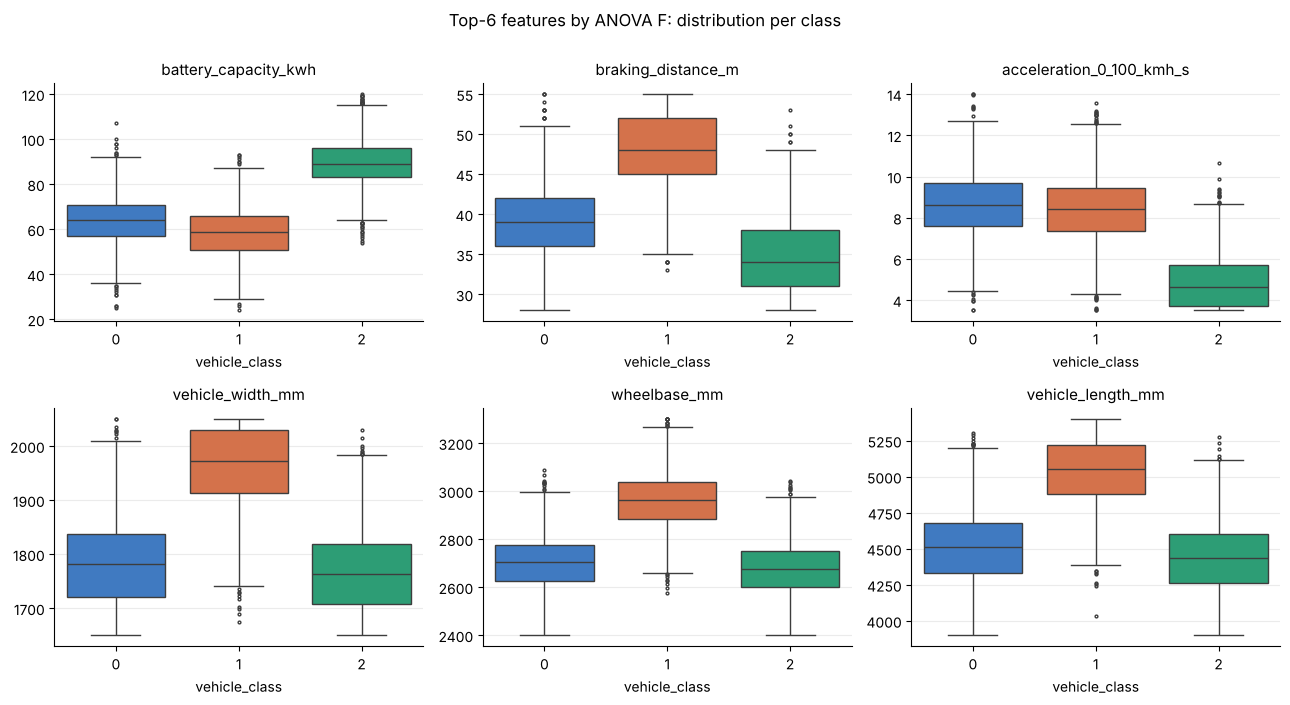

In [4]:
# ---------- 2b. Distributions by class: boxplots of the 6 most informative features ----------
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, f in zip(axes.ravel(), TOP):
    sns.boxplot(data=train, x=TARGET, y=f, hue=TARGET, palette=CLASS_COLORS, legend=False,
                linewidth=1, fliersize=2, ax=ax)
    ax.set_title(f); ax.set_xlabel("vehicle_class"); ax.set_ylabel("")
fig.suptitle("Top-6 features by ANOVA F: distribution per class", y=1.0)
plt.tight_layout(); plt.show()

Share of rows sitting exactly on the feature minimum or maximum:
 ground_clearance_mm          23.1 %
cargo_capacity_l             12.6 %
acceleration_0_100_kmh_s      7.1 %
vehicle_width_mm              6.1 %
tire_width_mm                 4.5 %
city_fuel_efficiency_kmpl     4.1 %
dtype: str


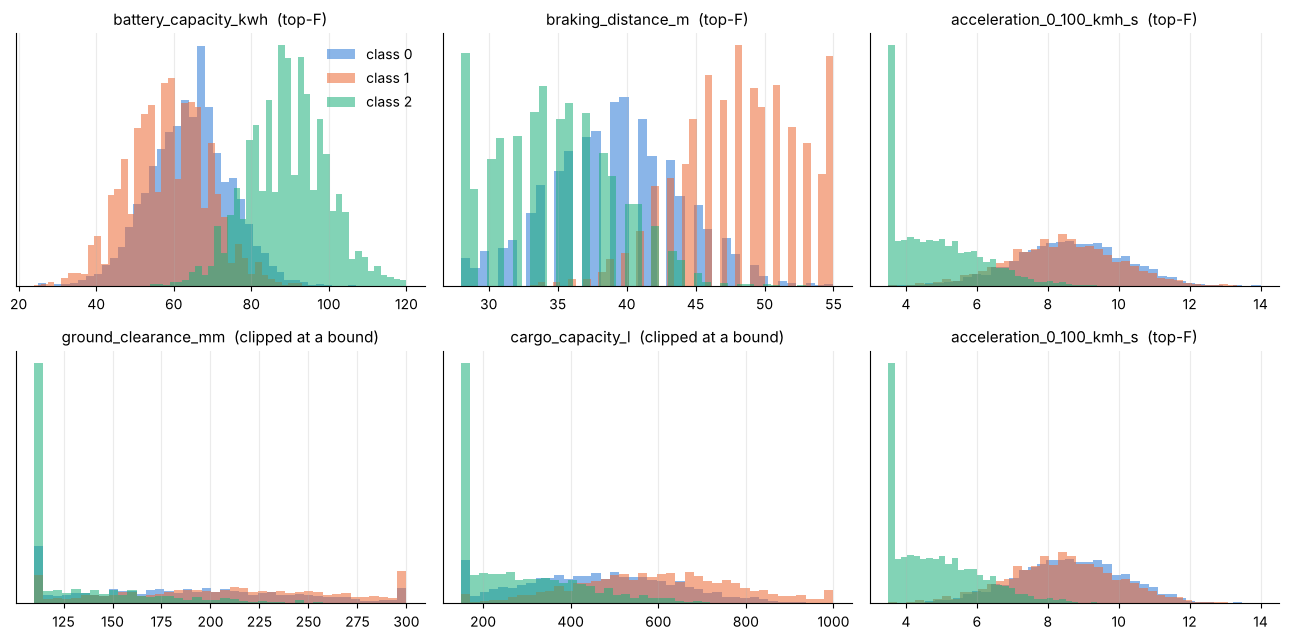

In [5]:
# ---------- 2c. Histograms: shapes matter for the Gaussian assumption (NB / LDA / QDA) ----------
# pick the 3 features with the largest pile-up of rows exactly at their min or max (clipped values)
pile = ((X == X.min()).mean().combine((X == X.max()).mean(), max)).sort_values(ascending=False)
HIST = TOP[:3] + pile.index[:3].tolist()
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, f in zip(axes.ravel(), HIST):
    for c in (0, 1, 2):
        ax.hist(train.loc[y == c, f], bins=40, alpha=0.55, color=CLASS_COLORS[c], label=f"class {c}", density=True)
    ax.set_title(f + ("  (top-F)" if f in TOP[:3] else "  (clipped at a bound)")); ax.set_yticks([])
axes[0, 0].legend()
plt.tight_layout(); plt.show()
print("Share of rows sitting exactly on the feature minimum or maximum:\n", (pile.head(6) * 100).round(1).astype(str) + " %")

14 feature pairs with |r| > 0.9:


r
torque_nm            horsepower_hp          0.959
                     engine_displacement_l  0.952
vehicle_width_mm     wheelbase_mm           0.952
horsepower_hp        engine_displacement_l  0.950
vehicle_length_mm    wheelbase_mm           0.949
wheelbase_mm         vehicle_weight_kg      0.945
vehicle_width_mm     vehicle_length_mm      0.937
vehicle_length_mm    vehicle_weight_kg      0.935
vehicle_width_mm     vehicle_weight_kg      0.929
fuel_tank_capacity_l vehicle_length_mm      0.914
                     wheelbase_mm           0.912
tire_width_mm        engine_displacement_l  0.912
fuel_tank_capacity_l vehicle_weight_kg      0.907
                     vehicle_width_mm       0.901

,overall r,within class 0,within class 1,within class 2
pair,,,,
horsepower_hp / torque_nm,0.959,0.931,0.935,0.924
wheelbase_mm / vehicle_width_mm,0.952,0.897,0.875,0.890


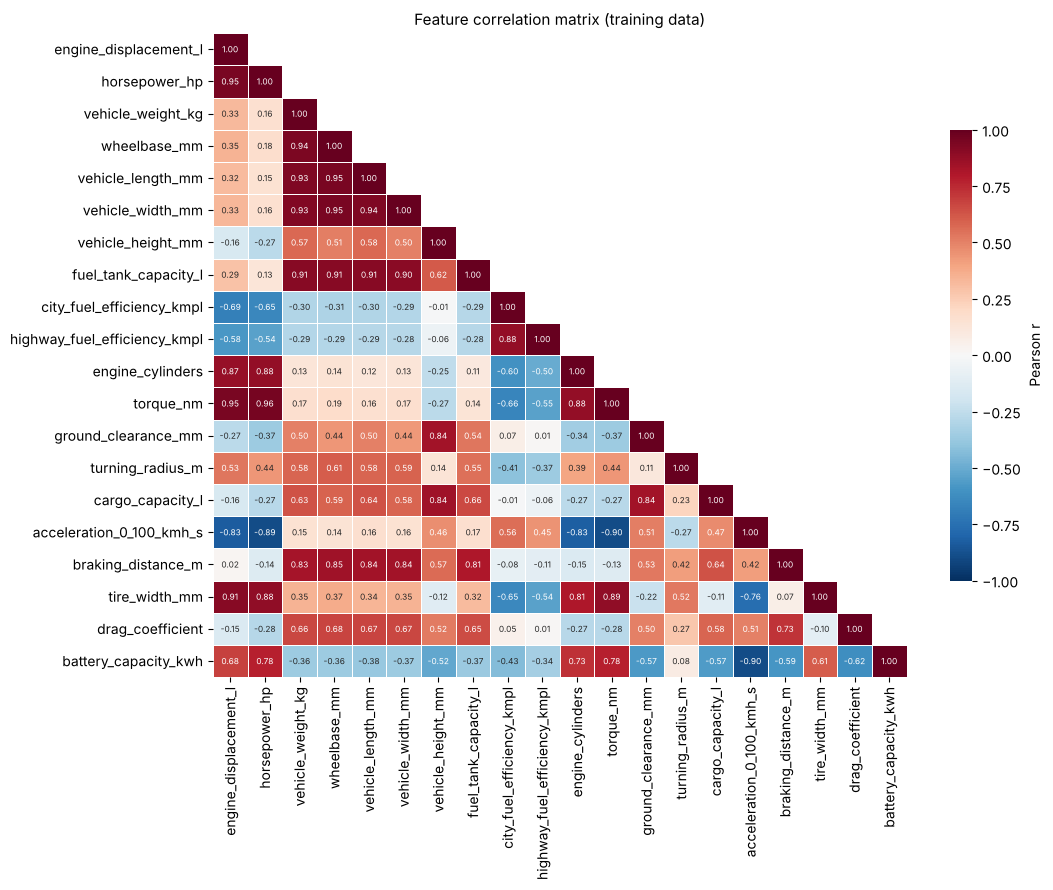

In [6]:
# ---------- 2d. Correlation heatmap (all 20 features) ----------
corr = X.corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)           # show lower triangle only
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 6}, linewidths=0.4, cbar_kws={"shrink": 0.7, "label": "Pearson r"}, ax=ax)
ax.set_title("Feature correlation matrix (training data)"); ax.grid(False)
plt.tight_layout(); plt.show()

# list of strongly correlated pairs
pairs = corr.where(~mask & ~np.eye(len(corr), dtype=bool)).stack()
strong = pairs[pairs.abs() > 0.9].sort_values(key=abs, ascending=False).rename("r").to_frame()
print(f"{len(strong)} feature pairs with |r| > 0.9:")
display(strong.round(3))

# Is the correlation only caused by the classes differing, or does it persist INSIDE each class?
# (Naive Bayes assumes independence *given the class*, so the within-class value is what counts.)
rows = []
for a, b in [("horsepower_hp", "torque_nm"), ("wheelbase_mm", "vehicle_width_mm")]:
    r = {"pair": f"{a} / {b}", "overall r": X[a].corr(X[b])}
    r.update({f"within class {c}": train.loc[y == c, a].corr(train.loc[y == c, b]) for c in (0, 1, 2)})
    rows.append(r)
display(pd.DataFrame(rows).set_index("pair").round(3))

**What the EDA shows**

* **Class profiles differ strongly.** Class 2 has the highest `horsepower_hp`, `torque_nm`, `engine_cylinders`, `battery_capacity_kwh`, `tire_width_mm` and the fastest `acceleration_0_100_kmh_s`, but the smallest `ground_clearance_mm` and `cargo_capacity_l`. Class 1 is the biggest and heaviest (length, width, wheelbase, weight, fuel tank, braking distance). Class 0 has the smallest engine, horsepower and torque and the best fuel economy, with body dimensions close to class 2. The top-F features separate the classes well, but the boxplots overlap, which is why the best accuracy is below 100%.
* **Several features are strongly correlated.** More than a dozen pairs have |r| > 0.9. Two examples are **horsepower and torque (r = 0.96)** and **wheelbase and width (r = 0.95)**. They are physically linked (bigger engine means more power and torque; a longer car is also wider and heavier), so these features carry largely the *same* information.
* **Why this matters for Naive Bayes.** Gaussian NB assumes the features are *independent given the class*. The second table shows the correlation stays high *within each class* (between about 0.87 and 0.94), so the assumption is clearly violated. NB then multiplies nearly duplicate likelihood terms, so correlated evidence is counted several times and its probabilities become over-confident, which tends to hurt accuracy. LDA, QDA and logistic regression model the correlations through the covariance matrix or the joint linear score, so they are not hurt in the same way. The flip side is that highly collinear features make the covariance matrices nearly singular (relevant for QDA/LDA regularisation) and make logistic-regression coefficients unstable, which is where ridge/lasso and feature selection can help.
* **Some features are clipped.** Several features have many rows exactly at their minimum or maximum (e.g. `ground_clearance_mm`), so they are not truly Gaussian. This is another small strike against the Gaussian-based classifiers (NB, LDA, QDA) but does not matter for trees.

## 3. Preprocessing

The next cells cover (a) outlier checks, (b) scaling inside a Pipeline, and (c) the feature selection experiments (forward selection and L1-based selection).

Rows with at least one IQR outlier: 135 of 7500 (1.8%)
Largest |z| anywhere: 3.62


,IQR outliers,|z| > 3,max |z|,rows at min,rows at max,skew
highway_fuel_efficiency_kmpl,49,9,3.29,24,1,0.03
turning_radius_m,39,14,3.50,1,2,-0.00
city_fuel_efficiency_kmpl,27,13,3.62,308,1,0.22
engine_displacement_l,18,5,3.29,44,1,-0.00
vehicle_weight_kg,13,9,3.15,222,4,0.34
vehicle_height_mm,8,5,3.58,245,1,0.09
wheelbase_mm,6,6,3.03,34,6,0.29
horsepower_hp,0,0,2.66,81,28,0.12
fuel_tank_capacity_l,0,0,2.00,266,267,0.18
vehicle_width_mm,0,0,1.81,411,456,0.25


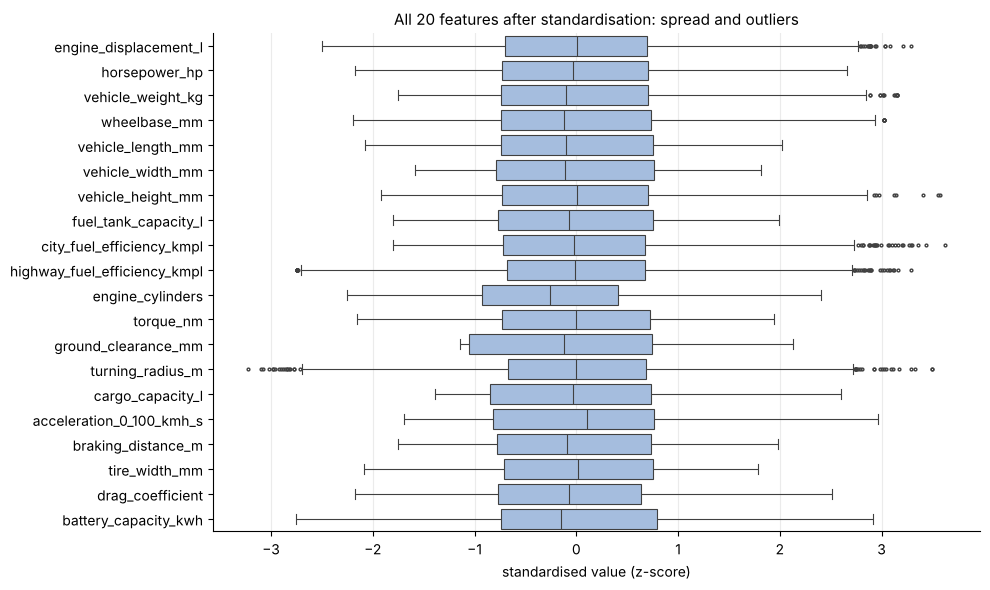

In [7]:
# ---------- 3a. Outlier check ----------
q1, q3 = X.quantile(0.25), X.quantile(0.75)
iqr = q3 - q1
is_iqr_out = (X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)       # Tukey rule
z = ((X - X.mean()) / X.std())
outliers = pd.DataFrame({
    "IQR outliers": is_iqr_out.sum(),
    "|z| > 3": (z.abs() > 3).sum(),
    "max |z|": z.abs().max().round(2),
    "rows at min": (X == X.min()).sum(),
    "rows at max": (X == X.max()).sum(),
    "skew": X.skew().round(2),
})
display(outliers.sort_values("IQR outliers", ascending=False))
print(f"Rows with at least one IQR outlier: {int(is_iqr_out.any(axis=1).sum())} of {len(X)} ({is_iqr_out.any(axis=1).mean():.1%})")
print(f"Largest |z| anywhere: {z.abs().max().max():.2f}")

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=z, orient="h", color="#9bbbe8", linewidth=0.8, fliersize=2, ax=ax)
ax.set_xlabel("standardised value (z-score)"); ax.set_title("All 20 features after standardisation: spread and outliers")
plt.tight_layout(); plt.show()

**Decision on outliers: keep all rows.**

* Only 1.8% of rows have a single feature outside the 1.5×IQR fences, and no value has |z| above about 3.6. Nothing is extreme or impossible; every feature stays inside a physically sensible range, and the flagged points are just the tails of near-symmetric distributions (small skew).
* The test file has the same ranges as the training file, so the model will see such values again. Deleting them would remove legitimate vehicles and make the training data less representative.
* Decision trees are unaffected by outliers (they only use rank order). For LDA/QDA/logistic regression the mild tails are acceptable, and standardising plus regularisation (ridge, shrinkage, `reg_param`) limits their influence. Winsorising or removing rows would therefore add risk without a clear gain.
* The more relevant finding is the opposite of outliers: many features are **clipped at their bounds** (hundreds or thousands of rows exactly at the min/max, see the table). That is a data-collection property we cannot undo, and it is why the Gaussian assumption is only approximate.

### 3b. Standardisation inside a `Pipeline`

* **Why standardise?** Feature scales differ by orders of magnitude (`drag_coefficient` is about 0.3, `vehicle_length_mm` about 4,500). Ridge/lasso penalties and the L1 selector treat all coefficients alike, so unscaled features would be penalised unevenly. LDA shrinkage and QDA `reg_param` shrink the covariance toward a (scaled) identity, which is only sensible when features are on comparable scales. Plain LDA, QDA and NB are invariant to scaling and trees ignore it, so scaling is harmless for them and keeps one uniform pipeline.
* **Why inside a Pipeline?** The `StandardScaler` mean/std (and any feature selector) must be estimated *only on the training part of each CV fold*. If we scaled the whole data set first, information from the validation fold (its mean and variance) would leak into training and make the CV scores slightly optimistic. With `Pipeline`, `cross_val_score` / `GridSearchCV` re-fit every step on each training fold only.
* **Trees** do not need scaling; the decision tree is fitted on raw features, which also keeps the plotted split thresholds interpretable (in real units).
* **Why not scale the test set separately?** The final pipeline is fitted on the full training set and `predict` applies the *training* mean/std to the test features.

### 3c. Feature selection experiments

We try two selection strategies, both **inside the CV pipeline** when scores are reported (section 5), so selection never sees the validation fold:

* **Forward selection:** start from no features and repeatedly add the feature that increases CV accuracy most (`SequentialFeatureSelector`, direction `forward`). It is a *wrapper* method: it asks the real classifier what helps.
* **L1-based selection:** fit an L1-penalised (lasso) logistic regression and keep the features with non-zero coefficients (`SelectFromModel`). It is an *embedded* method: selection happens as part of the fit, and the penalty strength C controls how many survive.

The next cell is a first look on the full training data using the cheap LDA classifier. It is **exploratory only** (it uses all rows, so its accuracies are slightly optimistic) and is only used to choose a sensible grid for the number of features *k*. The honest evaluation of the selectors is in section 5.

Peak at k=17; the smallest k within 0.2 points of the peak is k=10.


,feature added,CV accuracy
k,,
1,braking_distance_m,0.6877
2,acceleration_0_100_kmh_s,0.8351
3,wheelbase_mm,0.8727
4,vehicle_height_mm,0.8801
5,battery_capacity_kwh,0.8853
6,highway_fuel_efficiency_kmpl,0.8903
7,city_fuel_efficiency_kmpl,0.8907
8,turning_radius_m,0.8907
9,engine_displacement_l,0.8921


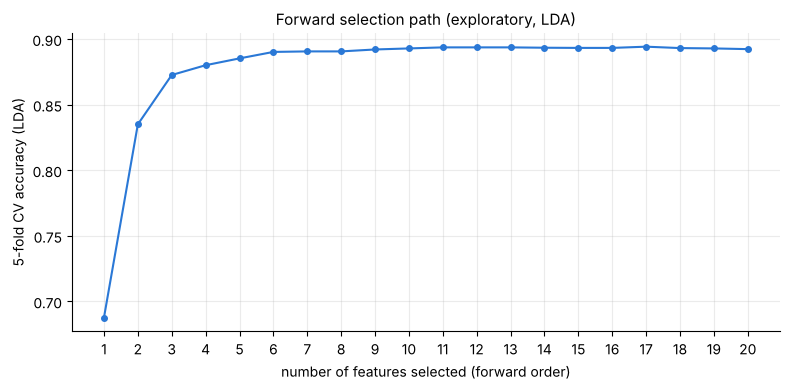

In [8]:
# ---------- 3c. Exploratory forward-selection path with LDA (greedy, one feature added at a time) ----------
def forward_selection_path(estimator, X, y, cv):
    # Greedy forward selection; returns the order of entry and the CV accuracy after each addition.
    selected, remaining, path = [], list(X.columns), []
    while remaining:
        scores = {f: cross_val_score(estimator, X[selected + [f]], y, cv=cv, scoring="accuracy").mean() for f in remaining}
        best_f = max(scores, key=scores.get)
        selected.append(best_f); remaining.remove(best_f)
        path.append((len(selected), best_f, scores[best_f]))
    return pd.DataFrame(path, columns=["k", "feature added", "CV accuracy"])

explore_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
lda_pipe = Pipeline([("scale", StandardScaler()), ("clf", LinearDiscriminantAnalysis())])
fs_path = forward_selection_path(lda_pipe, X, y, explore_cv)
display(fs_path.round(4).set_index("k"))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(fs_path["k"], fs_path["CV accuracy"], marker="o", ms=4, lw=1.5, color="#2a78d6")
ax.set_xlabel("number of features selected (forward order)"); ax.set_ylabel("5-fold CV accuracy (LDA)")
ax.set_xticks(range(1, 21)); ax.set_title("Forward selection path (exploratory, LDA)")
plt.tight_layout(); plt.show()
best_k = int(fs_path.loc[fs_path["CV accuracy"].idxmax(), "k"])
within = fs_path[fs_path["CV accuracy"] >= fs_path["CV accuracy"].max() - 0.002]["k"].min()
print(f"Peak at k={best_k}; the smallest k within 0.2 points of the peak is k={within}.")

In [9]:
# ---------- 3c. Exploratory L1-based selection: which features survive for different penalty strengths? ----------
def make_lr(l1=False, **kwargs):
    # Multinomial logistic regression with a ridge (L2) or lasso (L1) penalty.
    # scikit-learn >= 1.8 replaced `penalty=` by `l1_ratio=` (0 = ridge, 1 = lasso); older versions use `penalty=`.
    new_api = tuple(int(p) for p in sklearn.__version__.split(".")[:2]) >= (1, 8)
    if l1:
        pen = dict(l1_ratio=1.0) if new_api else dict(penalty="l1")
        return LogisticRegression(solver="saga", max_iter=5000, tol=1e-3, random_state=SEED, **pen, **kwargs)
    pen = dict(l1_ratio=0.0) if new_api else dict(penalty="l2")
    return LogisticRegression(solver="lbfgs", max_iter=5000, random_state=SEED, **pen, **kwargs)

Xs = StandardScaler().fit_transform(X)       # exploratory only: scaled on all training data
rows = []
for C in [0.001, 0.003, 0.01, 0.03, 0.1, 1]:
    sel = SelectFromModel(make_lr(l1=True, C=C), threshold=1e-6).fit(Xs, y)   # keep coef != 0
    rows.append({"C (L1)": C, "n features kept": int(sel.get_support().sum()),
                 "features dropped": ", ".join(np.array(FEATURES)[~sel.get_support()]) or "-"})
display(pd.DataFrame(rows).set_index("C (L1)"))

,n features kept,features dropped
C (L1),,
0.001,4,"engine_displacement_l, horsepower_hp, vehicle_weight_kg, vehicle_length_mm, vehicle_height_mm, fuel_tank_capacity_l, city_fuel_efficiency_kmpl, highway_fuel_efficiency_kmpl, engine_cylinders, torque_nm, ground_clearance_mm, turning_radius_m, cargo_capacity_l, braking_distance_m, tire_width_mm, drag_coefficient"
0.003,7,"engine_displacement_l, horsepower_hp, vehicle_weight_kg, fuel_tank_capacity_l, city_fuel_efficiency_kmpl, highway_fuel_efficiency_kmpl, engine_cylinders, torque_nm, ground_clearance_mm, turning_radius_m, cargo_capacity_l, tire_width_mm, drag_coefficient"
0.010,11,"engine_displacement_l, horsepower_hp, fuel_tank_capacity_l, city_fuel_efficiency_kmpl, engine_cylinders, torque_nm, ground_clearance_mm, cargo_capacity_l, tire_width_mm"
0.030,16,"engine_displacement_l, engine_cylinders, cargo_capacity_l, tire_width_mm"
0.100,20,-
1.000,20,-


**Reading the two experiments.** The forward path shows how quickly accuracy saturates: the first few features carry most of the signal and the curve flattens, so most of the remaining features are redundant (consistent with the strong correlations). The L1 table shows that a small C (strong penalty) removes many features, while for larger C almost nothing is dropped. We therefore tune the *number of features k* (forward) and the *penalty C* (L1) as hyper-parameters inside CV in section 5, rather than trusting these exploratory choices.

## 4. Validation scheme

* **Repeated stratified 5-fold CV, 3 repeats = 15 scores per model.** Stratification keeps the 1/3-1/3-1/3 class mix in every fold. Repeating with different shuffles reduces the dependence of the result on one particular split, and gives us 15 scores so we can report a mean *and* a standard deviation.
* **Same folds for every model.** We generate the 15 train/validation index pairs once (`cv_splits`) on the de-duplicated data and pass this *same list* to every `GridSearchCV` / `cross_val_score`. Scores are therefore directly comparable and can be compared fold by fold (paired).
* **Tuning.** `GridSearchCV` uses these same folds to pick hyper-parameters and the reported "best score" is the mean accuracy of the best setting. Because the best of several settings is chosen on the same folds, it is very slightly optimistic. The grids are small compared with 7,500 rows, so the effect is tiny, and section 6 re-scores the winners on *fresh* folds as a check.
* **Duplicates are removed beforehand** (section 1), so a vehicle can never appear in both the training and validation part of a fold. The demonstration below shows what happens otherwise.
* **Metric.** Accuracy (balanced classes). We report the mean and the standard deviation across the 15 folds.
* The confusion matrix of the best model is shown in section 6, once the best model is known; it uses out-of-fold predictions.

In [10]:
# ---------- 4. The CV splitter and helper functions shared by all models ----------
N_SPLITS, N_REPEATS = 5, 3
rskf = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)
cv_splits = list(rskf.split(X, y))             # materialised once -> identical folds for every model
n_val = len(cv_splits[0][1]); n_trn = len(cv_splits[0][0])
print(f"{len(cv_splits)} train/validation splits; each has {n_trn} training and {n_val} validation rows")
# sanity check: the first 5 splits (repeat 1) form a partition of the data -> used later for out-of-fold predictions
assert sorted(np.concatenate([v for _, v in cv_splits[:N_SPLITS]]).tolist()) == list(range(len(X)))

inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)   # inner CV for forward selection
cache = Memory(location=tempfile.mkdtemp(prefix="sfs_cache_"), verbose=0) # caches fitted selectors across grid points

results = {}        # model name -> dict(search, fold_scores, mean, std, params, secs)

def tune(name, estimator, grid):
    # Run GridSearchCV on the shared folds and store the best config + its 15 fold scores.
    t0 = time.time()
    gs = GridSearchCV(estimator, grid, cv=cv_splits, scoring="accuracy", n_jobs=-1, refit=True)
    gs.fit(X, y)
    b = gs.best_index_
    folds = np.array([gs.cv_results_[f"split{i}_test_score"][b] for i in range(len(cv_splits))])
    results[name] = dict(search=gs, fold_scores=folds, mean=folds.mean(), std=folds.std(ddof=1),
                         params=gs.best_params_, secs=time.time() - t0)
    print(f"[{name}] best CV accuracy {folds.mean():.4f} +/- {folds.std(ddof=1):.4f}  "
          f"(grid points: {len(gs.cv_results_['params'])}, {time.time()-t0:.0f}s)\n   best params: {gs.best_params_}")
    return gs

def curve_1d(gs, key):
    # mean/std of CV accuracy against one numeric hyper-parameter (other params at their tuned values)
    r = pd.DataFrame(gs.cv_results_)
    p = pd.DataFrame(list(r["params"]))
    best = gs.best_params_
    keep = np.ones(len(r), bool)
    for k, v in best.items():
        if k != key:
            keep &= (p[k].astype(str) == str(v)).values
    sub = r[keep].assign(x=p.loc[keep, key])
    sub = sub[sub["x"].map(lambda v: isinstance(v, (int, float, np.floating, np.integer)) and v is not None)]
    sub = sub.sort_values("x")
    return sub["x"].astype(float).values, sub["mean_test_score"].values, sub["std_test_score"].values

# Reference: untuned default models on the same folds (shows what tuning/regularisation buys)
defaults = {
    "LogReg (L2, C=1)": Pipeline([("scale", StandardScaler()), ("clf", make_lr(C=1.0))]),
    "LDA (default)":    Pipeline([("scale", StandardScaler()), ("clf", LinearDiscriminantAnalysis())]),
    "QDA (default)":    Pipeline([("scale", StandardScaler()), ("clf", QuadraticDiscriminantAnalysis())]),
    "Gaussian NB":      Pipeline([("scale", StandardScaler()), ("clf", GaussianNB())]),
    "Tree (max_depth=5)": DecisionTreeClassifier(max_depth=5, random_state=SEED),
}
default_scores = {}
for n, m in defaults.items():
    s = cross_val_score(m, X, y, cv=cv_splits, scoring="accuracy", n_jobs=-1)
    default_scores[n] = s
display(pd.DataFrame({n: {"mean accuracy": s.mean(), "std": s.std(ddof=1)} for n, s in default_scores.items()}).T.round(4))
print("Majority-class baseline accuracy:", round(y.value_counts(normalize=True).max(), 4))

15 train/validation splits; each has 6000 training and 1500 validation rows
Majority-class baseline accuracy: 0.3385


,mean accuracy,std
"LogReg (L2, C=1)",0.8937,0.0071
LDA (default),0.8922,0.0068
QDA (default),0.8850,0.0065
Gaussian NB,0.8468,0.0082
Tree (max_depth=5),0.8605,0.0073


**Why the duplicates were removed (demonstration).** The next cell scores the same models twice with the same CV recipe: once on the raw 10,000 rows (copies can sit on both sides of a split) and once on the 7,500 unique rows. A large gap means the raw-data score is partly memorisation.

In [11]:
# ---------- 4b. Leakage demonstration: raw rows (with duplicate copies) vs unique rows ----------
Xr, yr = train_raw[FEATURES], train_raw[TARGET]
raw_splits = list(RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED).split(Xr, yr))
demo = {"LDA":                       Pipeline([("scale", StandardScaler()), ("clf", LinearDiscriminantAnalysis())]),
        "QDA":                       Pipeline([("scale", StandardScaler()), ("clf", QuadraticDiscriminantAnalysis())]),
        "Decision tree (unpruned)":  DecisionTreeClassifier(random_state=SEED)}
rows = []
for n, m in demo.items():
    raw_acc = cross_val_score(m, Xr, yr, cv=raw_splits, scoring="accuracy", n_jobs=-1).mean()
    uni_acc = cross_val_score(m, X, y, cv=cv_splits, scoring="accuracy", n_jobs=-1).mean()
    rows.append({"model": n, "CV acc, raw 10,000 rows": raw_acc, "CV acc, 7,500 unique rows": uni_acc, "inflation": raw_acc - uni_acc})
display(pd.DataFrame(rows).set_index("model").round(4))

,"CV acc, raw 10,000 rows","CV acc, 7,500 unique rows",inflation
model,,,
LDA,0.8935,0.8922,0.0013
QDA,0.8886,0.8850,0.0036
Decision tree (unpruned),0.8967,0.8248,0.0719


## 5. Models

Every model is tuned with `GridSearchCV` on the shared folds (`cv_splits`). Each cell reports the best mean CV accuracy (± std over the 15 folds) and stores it in the `results` dictionary used for the final table in section 6. All pipelines start with `StandardScaler`, except the decision tree (see 3b).

### 5.1 Logistic regression with ridge (L2) penalty

Multinomial logistic regression models `log P(class k | x) - log P(class 0 | x)` as a *linear* function of the features. The ridge penalty adds `(1/C) * sum(beta^2)` to the loss: it shrinks the coefficients and keeps them stable when features are strongly correlated (here horsepower/torque and so on). **C is the inverse regularisation strength** (small C = strong shrinkage). We tune C on a log grid from 1e-4 to 1e2.

[Logistic regression (ridge, L2)] best CV accuracy 0.8943 +/- 0.0077  (grid points: 13, 5s)
   best params: {'clf__C': np.float64(0.1)}


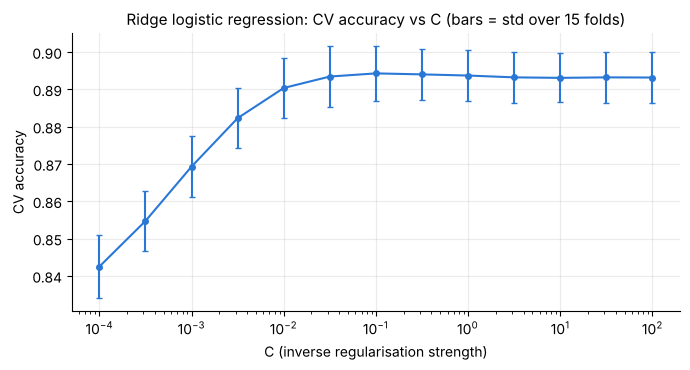

In [12]:
# ---------- 5.1 Logistic regression, ridge (L2) ----------
ridge_pipe = Pipeline([("scale", StandardScaler()), ("clf", make_lr(l1=False, C=1.0))])
gs_ridge = tune("Logistic regression (ridge, L2)", ridge_pipe, {"clf__C": np.logspace(-4, 2, 13)})

cs, m, s = curve_1d(gs_ridge, "clf__C")
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.errorbar(cs, m, yerr=s, marker="o", ms=4, lw=1.5, capsize=2, color="#2a78d6")
ax.set_xscale("log"); ax.set_xlabel("C (inverse regularisation strength)"); ax.set_ylabel("CV accuracy")
ax.set_title("Ridge logistic regression: CV accuracy vs C (bars = std over 15 folds)")
plt.tight_layout(); plt.show()

### 5.2 Logistic regression with lasso (L1) penalty

The lasso penalty `(1/C) * sum(|beta|)` shrinks some coefficients **exactly to zero**, so it performs feature selection while fitting. We tune C and then inspect which features are zeroed out. Because the best C may keep nearly all features, we also report the sparsest model that is still within one standard error of the best score (the "one-standard-error rule"), which is a common way to prefer a simpler model when accuracy differences are within noise.

[Logistic regression (lasso, L1)] best CV accuracy 0.8934 +/- 0.0069  (grid points: 9, 14s)
   best params: {'clf__C': np.float64(0.31622776601683794)}
Best C = 0.316228: 0 of 20 features have a zero coefficient in all 3 classes: none

1-SE rule: C = 0.1 (CV acc 0.8925) keeps 20 features.
Zeroed out: none


,class 0,class 1,class 2
engine_displacement_l,0.000,-0.234,0.877
horsepower_hp,0.000,-0.235,0.632
vehicle_weight_kg,0.000,0.541,-0.265
wheelbase_mm,0.000,1.912,-1.250
vehicle_length_mm,0.000,1.087,-0.313
vehicle_width_mm,0.000,0.901,0.000
vehicle_height_mm,0.727,-0.177,0.000
fuel_tank_capacity_l,0.000,0.294,-0.138
city_fuel_efficiency_kmpl,0.000,-0.276,0.270
highway_fuel_efficiency_kmpl,0.000,-0.077,0.558


,CV accuracy,features kept,zeroed in all classes
C,,,
0.001000,0.8593,4,"engine_displacement_l, horsepower_hp, vehicle_weight_kg, vehicle_length_mm, vehicle_height_mm, fuel_tank_capacity_l, city_fuel_efficiency_kmpl, highway_fuel_efficiency_kmpl, engine_cylinders, torque_nm, ground_clearance_mm, turning_radius_m, cargo_capacity_l, braking_distance_m, tire_width_mm, drag_coefficient"
0.003162,0.8646,7,"engine_displacement_l, horsepower_hp, vehicle_weight_kg, fuel_tank_capacity_l, city_fuel_efficiency_kmpl, highway_fuel_efficiency_kmpl, engine_cylinders, torque_nm, ground_clearance_mm, turning_radius_m, cargo_capacity_l, tire_width_mm, drag_coefficient"
0.010000,0.8818,11,"engine_displacement_l, horsepower_hp, fuel_tank_capacity_l, city_fuel_efficiency_kmpl, engine_cylinders, torque_nm, ground_clearance_mm, cargo_capacity_l, tire_width_mm"
0.031623,0.8894,16,"engine_displacement_l, engine_cylinders, cargo_capacity_l, tire_width_mm"
0.100000,0.8925,20,-
0.316228,0.8934,20,-
1.000000,0.8932,20,-
3.162278,0.8930,20,-
10.000000,0.8932,20,-


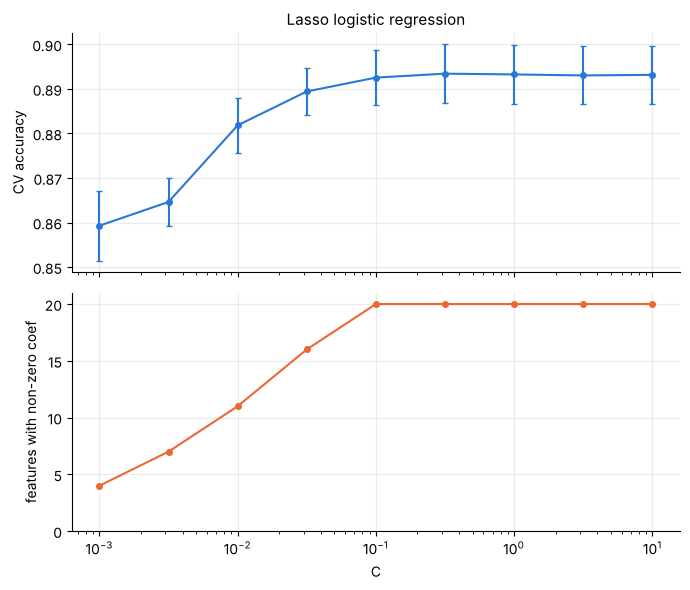

In [13]:
# ---------- 5.2 Logistic regression, lasso (L1) ----------
lasso_pipe = Pipeline([("scale", StandardScaler()), ("clf", make_lr(l1=True, C=1.0))])
gs_lasso = tune("Logistic regression (lasso, L1)", lasso_pipe, {"clf__C": np.logspace(-3, 1, 9)})

# Which features does each C zero out? (refit on all training data for display only)
cs = np.array(sorted(gs_lasso.param_grid["clf__C"]))
n_nonzero, coefs = [], {}
for C in cs:
    p = clone(lasso_pipe).set_params(clf__C=C).fit(X, y)
    cf = p.named_steps["clf"].coef_                    # shape (3 classes, 20 features)
    coefs[C] = cf; n_nonzero.append(int((np.abs(cf).sum(axis=0) > 0).sum()))

res = pd.DataFrame(gs_lasso.cv_results_)
res["C"] = [d["clf__C"] for d in res["params"]]; res = res.sort_values("C")
fig, axes = plt.subplots(2, 1, figsize=(7, 6), sharex=True)
axes[0].errorbar(res["C"], res["mean_test_score"], yerr=res["std_test_score"], marker="o", ms=4, capsize=2, color="#2a78d6")
axes[0].set_ylabel("CV accuracy"); axes[0].set_title("Lasso logistic regression")
axes[1].plot(cs, n_nonzero, marker="o", ms=4, color="#eb6834"); axes[1].set_ylabel("features with non-zero coef")
axes[1].set_xscale("log"); axes[1].set_xlabel("C"); axes[1].set_ylim(0, 21)
plt.tight_layout(); plt.show()

# Best C: coefficient table, zeroed features
best_C = results["Logistic regression (lasso, L1)"]["params"]["clf__C"]
coef_best = pd.DataFrame(coefs[best_C].T, index=FEATURES, columns=[f"class {k}" for k in range(3)])
zero_all = coef_best.index[(coef_best == 0).all(axis=1)].tolist()
print(f"Best C = {best_C:g}: {len(zero_all)} of 20 features have a zero coefficient in all 3 classes: {zero_all or 'none'}")
display(coef_best.round(3))

# Accuracy vs sparsity: what does each C keep / zero out? (a feature is "zeroed" only if it is 0 for ALL classes)
tab = []
for C in cs:
    used = np.abs(coefs[C]).sum(axis=0) > 0
    tab.append({"C": C, "CV accuracy": res.loc[res["C"] == C, "mean_test_score"].iloc[0], "features kept": int(used.sum()),
                "zeroed in all classes": ", ".join(np.array(FEATURES)[~used]) or "-"})
display(pd.DataFrame(tab).set_index("C").round(4))

# One-standard-error rule: smallest-model C whose mean score is within 1 SE of the best
se = results["Logistic regression (lasso, L1)"]["std"] / np.sqrt(len(cv_splits))
ok = res[res["mean_test_score"] >= res["mean_test_score"].max() - se]
C_sparse = ok["C"].min()
cf = coefs[C_sparse]; kept = np.array(FEATURES)[np.abs(cf).sum(axis=0) > 0]
dropped = np.array(FEATURES)[np.abs(cf).sum(axis=0) == 0]
print(f"\n1-SE rule: C = {C_sparse:g} (CV acc {ok.loc[ok['C'].idxmin(), 'mean_test_score']:.4f}) keeps {len(kept)} features.")
print("Zeroed out:", ", ".join(dropped) if len(dropped) else "none")
results["Logistic regression (lasso, L1)"]["zeroed_best"] = zero_all
results["Logistic regression (lasso, L1)"]["n_kept_1se"] = len(kept)

### 5.3 Linear Discriminant Analysis (LDA)

LDA models each class as a Gaussian with its **own mean but one shared covariance matrix**; Bayes' rule then gives linear class boundaries. With `solver="lsqr"` we can use **shrinkage**: the covariance is replaced by `(1 - s) * Sigma_hat + s * (average variance) * I`, which stabilises the estimate when features are highly correlated. We tune the shrinkage `s` in {None, `'auto'` (Ledoit-Wolf), and fixed values}, first on all features, then on two selected subsets:

* **forward selection** inside the pipeline (tuning the number of features *k*, with LDA as the selecting classifier and a 3-fold inner CV);
* **L1-based selection** inside the pipeline (tuning the L1 penalty C of the selector).

`Pipeline(memory=...)` caches the fitted selector so the shrinkage values do not repeat the expensive forward search.

[LDA (all features)] best CV accuracy 0.8939 +/- 0.0083  (grid points: 10, 2s)
   best params: {'clf__shrinkage': 0.1}


,mean_test_score,std_test_score
shrinkage,,
None,0.8922,0.0066
auto,0.8922,0.0066
0.01,0.8925,0.0065
0.05,0.8934,0.0074
0.1,0.8939,0.0080
0.2,0.8918,0.0086
0.3,0.8883,0.0083
0.5,0.8824,0.0081
0.7,0.8709,0.0074


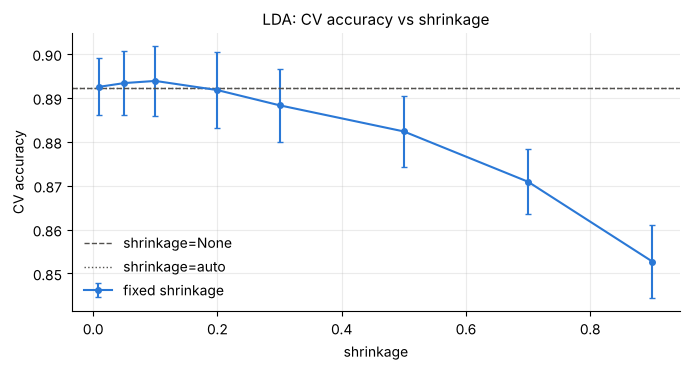

In [14]:
# ---------- 5.3a LDA on all features ----------
shrink_grid = [None, "auto", 0.01, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9]
lda_all = Pipeline([("scale", StandardScaler()), ("clf", LinearDiscriminantAnalysis(solver="lsqr"))])
gs_lda = tune("LDA (all features)", lda_all, {"clf__shrinkage": shrink_grid})

r = pd.DataFrame(gs_lda.cv_results_); r["shrinkage"] = [d["clf__shrinkage"] for d in r["params"]]
display(r[["shrinkage", "mean_test_score", "std_test_score"]].round(4).set_index("shrinkage"))

xs, m, s = curve_1d(gs_lda, "clf__shrinkage")
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.errorbar(xs, m, yerr=s, marker="o", ms=4, capsize=2, color="#2a78d6", label="fixed shrinkage")
for lab, ls in [(None, "--"), ("auto", ":")]:
    v = r.loc[r["shrinkage"].apply(lambda t: t == lab), "mean_test_score"].values[0]
    ax.axhline(v, ls=ls, color="#52514e", lw=1, label=f"shrinkage={lab}")
ax.set_xlabel("shrinkage"); ax.set_ylabel("CV accuracy"); ax.legend(); ax.set_title("LDA: CV accuracy vs shrinkage")
plt.tight_layout(); plt.show()

In [15]:
# ---------- 5.3b LDA on a forward-selected subset (selection re-done inside every CV training fold) ----------
sfs_lda = SequentialFeatureSelector(LinearDiscriminantAnalysis(), n_features_to_select=8, direction="forward",
                                    scoring="accuracy", cv=inner_cv, n_jobs=1)
lda_fwd = Pipeline([("scale", StandardScaler()), ("select", sfs_lda),
                    ("clf", LinearDiscriminantAnalysis(solver="lsqr"))], memory=cache)
gs_lda_fwd = tune("LDA (forward-selected subset)", lda_fwd,
                  {"select__n_features_to_select": [4, 6, 8, 10, 14], "clf__shrinkage": [None, "auto", 0.1, 0.3]})

sel_names = np.array(FEATURES)[gs_lda_fwd.best_estimator_.named_steps["select"].get_support()]
print(f"\nForward-selected features when fitted on all training data (k = {len(sel_names)}):\n  ", ", ".join(sel_names))

r = pd.DataFrame(gs_lda_fwd.cv_results_)
r["k"] = [d["select__n_features_to_select"] for d in r["params"]]
display(r.groupby("k")["mean_test_score"].max().round(4).rename("best CV acc for this k (over shrinkage)").to_frame())

[LDA (forward-selected subset)] best CV accuracy 0.8890 +/- 0.0070  (grid points: 20, 106s)
   best params: {'clf__shrinkage': None, 'select__n_features_to_select': 10}

Forward-selected features when fitted on all training data (k = 10):
   engine_displacement_l, horsepower_hp, wheelbase_mm, vehicle_height_mm, highway_fuel_efficiency_kmpl, torque_nm, turning_radius_m, acceleration_0_100_kmh_s, braking_distance_m, battery_capacity_kwh


,best CV acc for this k (over shrinkage)
k,
4,0.8803
6,0.8887
8,0.8887
10,0.8890
14,0.8890


In [16]:
# ---------- 5.3c LDA on an L1-selected subset ----------
lda_l1 = Pipeline([("scale", StandardScaler()),
                   ("select", SelectFromModel(make_lr(l1=True, C=0.05), threshold=1e-6)),   # keep features with coef != 0
                   ("clf", LinearDiscriminantAnalysis(solver="lsqr"))], memory=cache)
gs_lda_l1 = tune("LDA (L1-selected subset)", lda_l1,
                 {"select__estimator__C": [0.003, 0.01, 0.03, 0.1, 0.3], "clf__shrinkage": [None, "auto", 0.1]})

sel_l1 = gs_lda_l1.best_estimator_.named_steps["select"]
kept = np.array(FEATURES)[sel_l1.get_support()]
print(f"\nL1 selector at best C keeps {len(kept)} features (fitted on all training data):\n  ", ", ".join(kept))
print("Dropped:", ", ".join(np.array(FEATURES)[~sel_l1.get_support()]) or "none")

# How many features does the selector keep at each C, and what accuracy does LDA reach with them?
r = pd.DataFrame(gs_lda_l1.cv_results_); r["C (selector)"] = [d["select__estimator__C"] for d in r["params"]]
n_kept = {C: int(clone(lda_l1.named_steps["select"]).set_params(estimator__C=C).fit(StandardScaler().fit_transform(X), y).get_support().sum())
          for C in sorted(r["C (selector)"].unique())}      # selector fitted on all training data, display only
l1_tab = r.groupby("C (selector)")["mean_test_score"].max().rename("best CV accuracy (over shrinkage)").to_frame()
l1_tab["features kept"] = pd.Series(n_kept)
display(l1_tab.round(4))

[LDA (L1-selected subset)] best CV accuracy 0.8939 +/- 0.0083  (grid points: 15, 6s)
   best params: {'clf__shrinkage': 0.1, 'select__estimator__C': 0.1}

L1 selector at best C keeps 20 features (fitted on all training data):
   engine_displacement_l, horsepower_hp, vehicle_weight_kg, wheelbase_mm, vehicle_length_mm, vehicle_width_mm, vehicle_height_mm, fuel_tank_capacity_l, city_fuel_efficiency_kmpl, highway_fuel_efficiency_kmpl, engine_cylinders, torque_nm, ground_clearance_mm, turning_radius_m, cargo_capacity_l, acceleration_0_100_kmh_s, braking_distance_m, tire_width_mm, drag_coefficient, battery_capacity_kwh
Dropped: none


,best CV accuracy (over shrinkage),features kept
C (selector),,
0.003,0.8836,7
0.010,0.8868,11
0.030,0.8911,16
0.100,0.8939,20
0.300,0.8939,20


### 5.4 Quadratic Discriminant Analysis (QDA)

QDA is like LDA but gives **each class its own covariance matrix**, so class boundaries are quadratic. It is more flexible but needs to estimate 3 covariance matrices (about 210 numbers each), which is risky with strongly correlated features. `reg_param` regularises each class covariance: `Sigma_k = (1 - r) * Sigma_k + r * I`. `reg_param = 0` is plain QDA; larger values move it toward a spherical Gaussian. We tune `reg_param` on [0, 1].

[QDA] best CV accuracy 0.8895 +/- 0.0072  (grid points: 12, 2s)
   best params: {'clf__reg_param': 0.1}


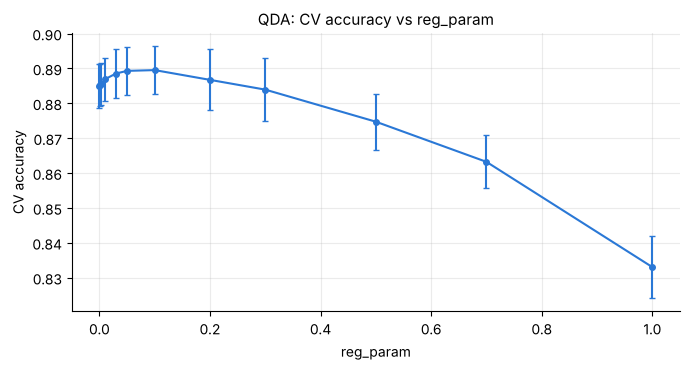

In [17]:
# ---------- 5.4 QDA ----------
qda_pipe = Pipeline([("scale", StandardScaler()), ("clf", QuadraticDiscriminantAnalysis())])
reg_grid = [0, 0.001, 0.003, 0.01, 0.03, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 1.0]
gs_qda = tune("QDA", qda_pipe, {"clf__reg_param": reg_grid})

xs, m, s = curve_1d(gs_qda, "clf__reg_param")
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.errorbar(xs, m, yerr=s, marker="o", ms=4, capsize=2, color="#2a78d6")
ax.set_xlabel("reg_param"); ax.set_ylabel("CV accuracy"); ax.set_title("QDA: CV accuracy vs reg_param")
plt.tight_layout(); plt.show()

### 5.5 Decision tree

A tree recursively splits the data with axis-parallel thresholds, choosing the split that most reduces impurity (**gini** or **entropy**). A deep tree can fit the training set perfectly (high variance), so we control complexity with `max_depth`, `min_samples_leaf` (minimum leaf size) and `ccp_alpha` (cost-complexity pruning: prune branches whose impurity gain per leaf is below alpha). We tune all four, including the criterion.

In [18]:
# ---------- 5.5 Decision tree: grid over depth, leaf size, pruning and criterion ----------
tree_grid = {"max_depth": [3, 4, 5, 6, 8, 10, 12, None],
             "min_samples_leaf": [1, 5, 10, 20, 40],
             "ccp_alpha": [0.0, 0.0005, 0.001, 0.002],
             "criterion": ["gini", "entropy"]}
gs_tree = tune("Decision tree", DecisionTreeClassifier(random_state=SEED), tree_grid)

# best score for each criterion
r = pd.DataFrame(gs_tree.cv_results_); r["criterion"] = [d["criterion"] for d in r["params"]]
display(r.groupby("criterion")["mean_test_score"].max().round(4).rename("best CV accuracy").to_frame())

[Decision tree] best CV accuracy 0.8627 +/- 0.0076  (grid points: 320, 196s)
   best params: {'ccp_alpha': 0.0005, 'criterion': 'gini', 'max_depth': 6, 'min_samples_leaf': 1}


,best CV accuracy
criterion,
entropy,0.8604
gini,0.8627


Best validation accuracy on the depth curve: 0.8627 at depth 6


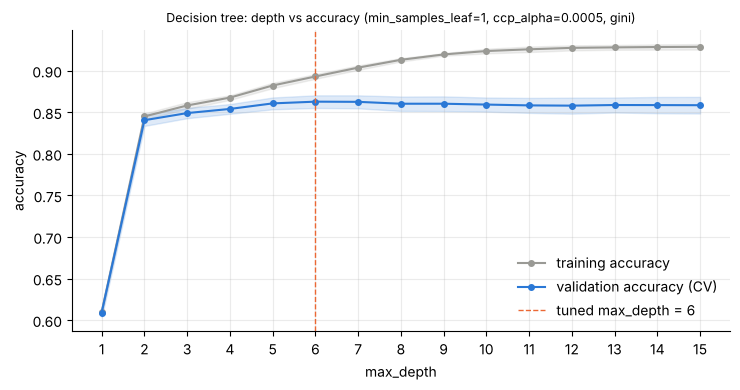

In [19]:
# ---------- 5.5 Validation accuracy vs tree depth (other hyper-parameters fixed at their tuned values) ----------
depths = list(range(1, 16))
tree_base = clone(gs_tree.best_estimator_).set_params(max_depth=None)
tr_sc, va_sc = validation_curve(tree_base, X, y, param_name="max_depth", param_range=depths,
                                cv=cv_splits, scoring="accuracy", n_jobs=-1)
fig, ax = plt.subplots(figsize=(7.5, 4))
for sc, lab, col in [(tr_sc, "training accuracy", "#9a9a95"), (va_sc, "validation accuracy (CV)", "#2a78d6")]:
    mu, sd = sc.mean(1), sc.std(1, ddof=1)
    ax.plot(depths, mu, marker="o", ms=4, lw=1.5, color=col, label=lab)
    ax.fill_between(depths, mu - sd, mu + sd, color=col, alpha=0.15)
bd = gs_tree.best_params_["max_depth"]
if bd is not None:
    ax.axvline(bd, color="#eb6834", ls="--", lw=1, label=f"tuned max_depth = {bd}")
ax.set_xlabel("max_depth"); ax.set_ylabel("accuracy"); ax.set_xticks(depths); ax.legend()
ax.set_title(f"Decision tree: depth vs accuracy (min_samples_leaf={gs_tree.best_params_['min_samples_leaf']}, "
             f"ccp_alpha={gs_tree.best_params_['ccp_alpha']}, {gs_tree.best_params_['criterion']})", fontsize=9)
plt.tight_layout(); plt.show()
va_mean = va_sc.mean(1)
print(f"Best validation accuracy on the depth curve: {va_mean.max():.4f} at depth {depths[int(va_mean.argmax())]}")

Tree depth = 6, leaves = 45, features used = 13 of 20
Top 5: battery_capacity_kwh, wheelbase_mm, acceleration_0_100_kmh_s, vehicle_height_mm, highway_fuel_efficiency_kmpl


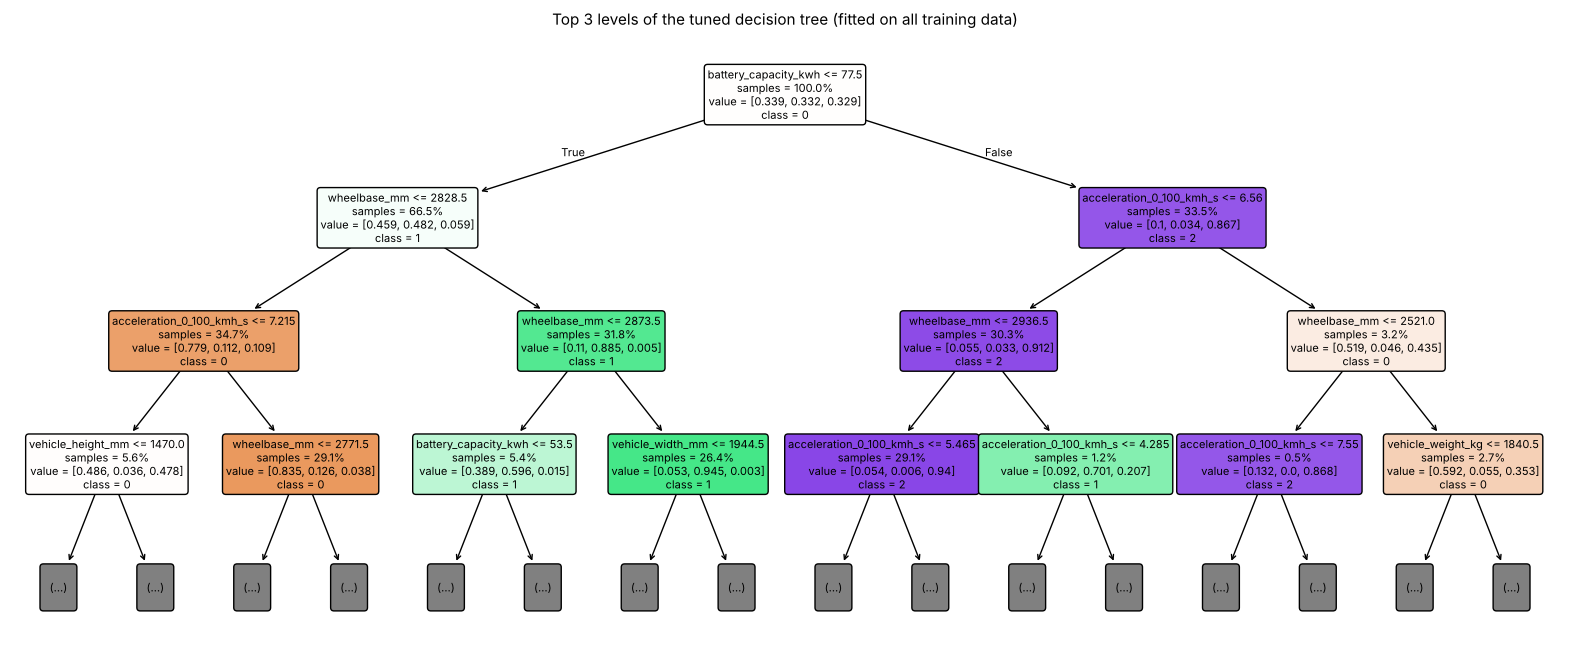

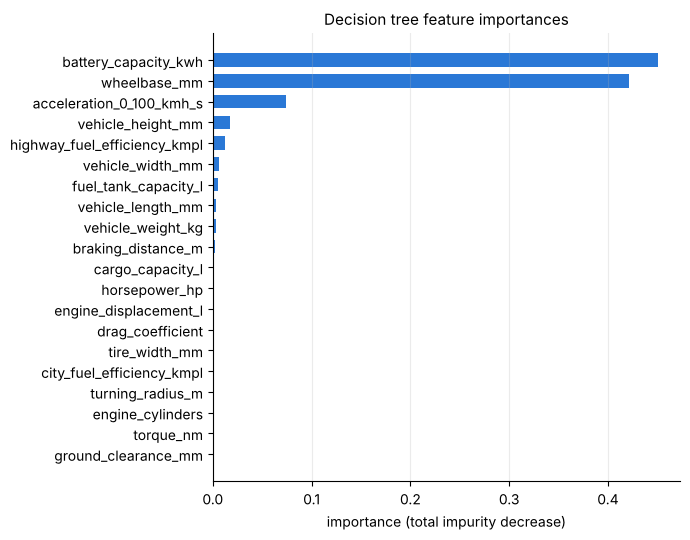

In [20]:
# ---------- 5.5 Top of the fitted tree and feature importances ----------
best_tree = gs_tree.best_estimator_            # already refitted on all training rows by GridSearchCV
fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(best_tree, max_depth=3, feature_names=FEATURES, class_names=["0", "1", "2"],
          filled=True, rounded=True, fontsize=8, impurity=False, proportion=True, ax=ax)
ax.set_title("Top 3 levels of the tuned decision tree (fitted on all training data)")
plt.show()

imp = pd.Series(best_tree.feature_importances_, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(imp.index, imp.values, color="#2a78d6", height=0.65); ax.set_xlabel("importance (total impurity decrease)")
ax.set_title("Decision tree feature importances"); ax.grid(axis="y", alpha=0)
plt.tight_layout(); plt.show()
print(f"Tree depth = {best_tree.get_depth()}, leaves = {best_tree.get_n_leaves()}, "
      f"features used = {(best_tree.feature_importances_ > 0).sum()} of 20")
print("Top 5:", ", ".join(imp.sort_values(ascending=False).index[:5]))

### 5.6 Gaussian Naive Bayes (baseline)

Naive Bayes applies Bayes' rule with the **naive assumption that features are conditionally independent given the class**; each feature is modelled by a 1-D Gaussian per class, so there are only 2 parameters per feature per class. It is fast and needs little data, but section 2 showed strong within-class correlations, so we expect it to be the weakest model. As the baseline we report the default model; the only hyper-parameter, `var_smoothing` (added to every variance), is tuned for completeness.

As an extra experiment we also run NB after **forward selection**: if the features are redundant copies of each other, keeping only a few decorrelated ones should *help* NB, which would directly support the independence argument.

In [21]:
# ---------- 5.6 Gaussian NB (baseline) ----------
nb_pipe = Pipeline([("scale", StandardScaler()), ("clf", GaussianNB())])
gs_nb = tune("Gaussian Naive Bayes", nb_pipe, {"clf__var_smoothing": np.logspace(-9, 0, 10)})
print(f"Default GaussianNB (var_smoothing=1e-9): {default_scores['Gaussian NB'].mean():.4f} "
      f"+/- {default_scores['Gaussian NB'].std(ddof=1):.4f}")

[Gaussian Naive Bayes] best CV accuracy 0.8468 +/- 0.0082  (grid points: 10, 2s)
   best params: {'clf__var_smoothing': np.float64(1e-09)}
Default GaussianNB (var_smoothing=1e-9): 0.8468 +/- 0.0082


In [22]:
# ---------- 5.6b Extra experiment: Gaussian NB on a forward-selected subset ----------
sfs_nb = SequentialFeatureSelector(GaussianNB(), n_features_to_select=6, direction="forward",
                                   scoring="accuracy", cv=inner_cv, n_jobs=1)
nb_fwd = Pipeline([("scale", StandardScaler()), ("select", sfs_nb), ("clf", GaussianNB())], memory=cache)
gs_nb_fwd = tune("Gaussian NB (forward-selected subset)", nb_fwd,
                 {"select__n_features_to_select": [2, 3, 4, 5, 6, 8, 10, 14]})
print("Selected on all training data:", ", ".join(np.array(FEATURES)[gs_nb_fwd.best_estimator_.named_steps["select"].get_support()]))
r = pd.DataFrame(gs_nb_fwd.cv_results_); r["k"] = [d["select__n_features_to_select"] for d in r["params"]]
display(r[["k", "mean_test_score", "std_test_score"]].set_index("k").round(4))

[Gaussian NB (forward-selected subset)] best CV accuracy 0.8708 +/- 0.0074  (grid points: 8, 125s)
   best params: {'select__n_features_to_select': 6}
Selected on all training data: wheelbase_mm, vehicle_width_mm, turning_radius_m, acceleration_0_100_kmh_s, braking_distance_m, battery_capacity_kwh


,mean_test_score,std_test_score
k,,
2,0.8356,0.0050
3,0.8640,0.0079
4,0.8686,0.0071
5,0.8698,0.0074
6,0.8708,0.0071
8,0.8678,0.0082
10,0.8666,0.0082
14,0.8615,0.0074


## 6. Results

All numbers below come from the **same 15 CV folds** (5-fold x 3 repeats on the 7,500 unique training rows). "Best Score Achieved" is the mean CV accuracy of the best hyper-parameter setting of each model, with the standard deviation over the 15 folds.

In [23]:
# ---------- 6a. Results table: Model | Best Score Achieved | Key observation ----------
def P(name):  # tuned hyper-parameters of one model, printed compactly
    return ", ".join(f"{k.split('__')[-1]}={v:.3g}" if isinstance(v, (int, float, np.floating)) else f"{k.split('__')[-1]}={v}"
                     for k, v in results[name]["params"].items())

OBS = {   # one-line takeaway per model; numbers are filled in from the results above
    "Logistic regression (ridge, L2)": f"Best at {P('Logistic regression (ridge, L2)')}; a linear boundary is enough and mild shrinkage copes with the correlated features. Top tier, tied with LDA and lasso.",
    "Logistic regression (lasso, L1)": f"Best at {P('Logistic regression (lasso, L1)')}; no feature is zeroed in all three classes ({len(results['Logistic regression (lasso, L1)']['zeroed_best'])} dropped), and stronger penalties that do drop features cost accuracy. Same level as ridge.",
    "LDA (all features)": f"Best at shrinkage={results['LDA (all features)']['params']['clf__shrinkage']}; shrinkage barely matters up to about 0.2 and hurts beyond that. Matches logistic regression, so shared-covariance Gaussians describe the classes well.",
    "LDA (forward-selected subset)": f"Best with k={results['LDA (forward-selected subset)']['params']['select__n_features_to_select']} of 20 features and shrinkage={results['LDA (forward-selected subset)']['params']['clf__shrinkage']}; about {100*(results['LDA (all features)']['mean']-results['LDA (forward-selected subset)']['mean']):.1f} points below all features, because the dropped correlated features still add a little information.",
    "LDA (L1-selected subset)": f"Best L1 selector setting keeps all {int(l1_tab['features kept'].loc[results['LDA (L1-selected subset)']['params']['select__estimator__C']])} features, so it equals LDA on all features; stronger sparsity lowered accuracy.",
    "QDA": f"Best at reg_param={results['QDA']['params']['clf__reg_param']:.3g} (default QDA: {default_scores['QDA (default)'].mean():.4f}); class-specific covariances add flexibility that is not needed here, so it stays slightly below LDA.",
    "Decision tree": f"Best at {P('Decision tree')}; clearly below the linear models: axis-parallel splits approximate oblique boundaries poorly, and deeper trees overfit (see depth curve).",
    "Gaussian Naive Bayes": f"Baseline and weakest model; the independence assumption is badly violated by features that are correlated at r of about 0.9 within each class. Tuning var_smoothing did not help.",
    "Gaussian NB (forward-selected subset)": f"Extra experiment: keeping only {results['Gaussian NB (forward-selected subset)']['params']['select__n_features_to_select']} less redundant features lifts NB by {100*(results['Gaussian NB (forward-selected subset)']['mean']-results['Gaussian Naive Bayes']['mean']):.1f} points, supporting the correlation explanation, but it remains below the linear models.",
}


summary = pd.DataFrame({"Model": list(results),
                        "mean": [results[n]["mean"] for n in results],
                        "std": [results[n]["std"] for n in results]}).sort_values("mean", ascending=False).reset_index(drop=True)
results_table = pd.DataFrame({
    "Model": summary["Model"],
    "Best Score Achieved": [f"{m:.4f} ± {s:.4f}" for m, s in zip(summary["mean"], summary["std"])],
    "Key observation": [OBS[n] for n in summary["Model"]],
})
display(results_table)

# plain Markdown version of the same table (copy/paste into a report)
print("\n| Model | Best Score Achieved | Key observation |\n|---|---|---|")
for _, r in results_table.iterrows():
    print(f"| {r['Model']} | {r['Best Score Achieved']} | {r['Key observation']} |")


| Model | Best Score Achieved | Key observation |
|---|---|---|
| Logistic regression (ridge, L2) | 0.8943 ± 0.0077 | Best at C=0.1; a linear boundary is enough and mild shrinkage copes with the correlated features. Top tier, tied with LDA and lasso. |
| LDA (all features) | 0.8939 ± 0.0083 | Best at shrinkage=0.1; shrinkage barely matters up to about 0.2 and hurts beyond that. Matches logistic regression, so shared-covariance Gaussians describe the classes well. |
| LDA (L1-selected subset) | 0.8939 ± 0.0083 | Best L1 selector setting keeps all 20 features, so it equals LDA on all features; stronger sparsity lowered accuracy. |
| Logistic regression (lasso, L1) | 0.8934 ± 0.0069 | Best at C=0.316; no feature is zeroed in all three classes (0 dropped), and stronger penalties that do drop features cost accuracy. Same level as ridge. |
| QDA | 0.8895 ± 0.0072 | Best at reg_param=0.1 (default QDA: 0.8850); class-specific covariances add flexibility that is not needed here, so it stays sl

,Model,Best Score Achieved,Key observation
0,"Logistic regression (ridge, L2)",0.8943 ± 0.0077,"Best at C=0.1; a linear boundary is enough and mild shrinkage copes with the correlated features. Top tier, tied with LDA and lasso."
1,LDA (all features),0.8939 ± 0.0083,"Best at shrinkage=0.1; shrinkage barely matters up to about 0.2 and hurts beyond that. Matches logistic regression, so shared-covariance Gaussians describe the classes well."
2,LDA (L1-selected subset),0.8939 ± 0.0083,"Best L1 selector setting keeps all 20 features, so it equals LDA on all features; stronger sparsity lowered accuracy."
3,"Logistic regression (lasso, L1)",0.8934 ± 0.0069,"Best at C=0.316; no feature is zeroed in all three classes (0 dropped), and stronger penalties that do drop features cost accuracy. Same level as ridge."
4,QDA,0.8895 ± 0.0072,"Best at reg_param=0.1 (default QDA: 0.8850); class-specific covariances add flexibility that is not needed here, so it stays slightly below LDA."
5,LDA (forward-selected subset),0.8890 ± 0.0070,"Best with k=10 of 20 features and shrinkage=None; about 0.5 points below all features, because the dropped correlated features still add a little information."
6,Gaussian NB (forward-selected subset),0.8708 ± 0.0074,"Extra experiment: keeping only 6 less redundant features lifts NB by 2.4 points, supporting the correlation explanation, but it remains below the linear models."
7,Decision tree,0.8627 ± 0.0076,"Best at ccp_alpha=0.0005, criterion=gini, max_depth=6, min_samples_leaf=1; clearly below the linear models: axis-parallel splits approximate oblique boundaries poorly, and deeper trees overfit (see depth curve)."
8,Gaussian Naive Bayes,0.8468 ± 0.0082,Baseline and weakest model; the independence assumption is badly violated by features that are correlated at r of about 0.9 within each class. Tuning var_smoothing did not help.


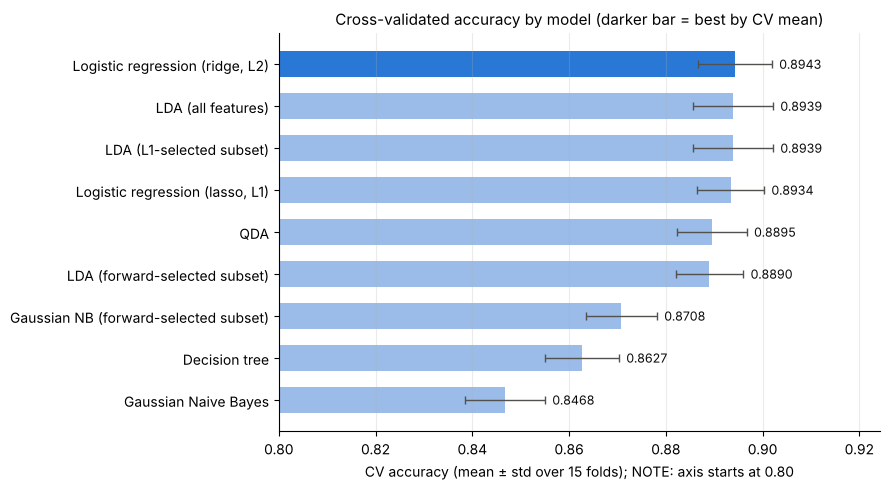

In [24]:
# ---------- 6b. Bar chart of CV accuracy with error bars (std over the 15 folds) ----------
plot_df = summary.sort_values("mean")                       # best model at the top of a horizontal bar chart
fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#2a78d6" if n == summary.loc[0, "Model"] else "#9bbbe8" for n in plot_df["Model"]]
ax.barh(plot_df["Model"], plot_df["mean"], xerr=plot_df["std"], color=colors, height=0.62,
        error_kw=dict(ecolor="#52514e", capsize=3, lw=1))
for i, (m, s) in enumerate(zip(plot_df["mean"], plot_df["std"])):
    ax.text(m + s + 0.0015, i, f"{m:.4f}", va="center", fontsize=9, color="#0b0b0b")
lo = min(0.80, np.floor((plot_df["mean"].min() - 0.03) * 50) / 50)
ax.set_xlim(lo, plot_df["mean"].max() + 0.03); ax.grid(axis="y", alpha=0)
ax.set_xlabel(f"CV accuracy (mean ± std over 15 folds); NOTE: axis starts at {lo:.2f}")
ax.set_title("Cross-validated accuracy by model (darker bar = best by CV mean)")
plt.tight_layout(); plt.show()

### Which differences are real and which are noise?

The standard deviation over folds (about 0.7 to 0.8 percentage points) is of the same size as many gaps between models, so we should not rank models by the third decimal. Because all models use the *same folds*, the fairest comparison is **paired**: for each fold take `score(best) - score(other)`.

Folds from repeated CV overlap in their training data, so a plain paired t-test would be too optimistic. We use the **Nadeau-Bengio corrected resampled t-test**, which inflates the variance by `(1/k + n_val/n_train)` (k = 15 folds). Treat the p-values as a rough guide; the table also shows a conservative Bonferroni-adjusted p (multiplied by the number of comparisons).

In [25]:
# ---------- 6c. Paired comparison of every model against the best one ----------
best_name = summary.loc[0, "Model"]
k = len(cv_splits); n_trn, n_val = len(cv_splits[0][0]), len(cv_splits[0][1])
rows = []
for n in summary["Model"][1:]:
    d = results[best_name]["fold_scores"] - results[n]["fold_scores"]          # per-fold paired difference
    var = d.var(ddof=1)
    t = d.mean() / np.sqrt((1 / k + n_val / n_trn) * var) if var > 0 else np.inf
    p = 2 * stats.t.sf(abs(t), df=k - 1)
    rows.append({"Model": n, "mean diff vs best": d.mean(), "std of diff": d.std(ddof=1),
                 "folds where best wins": f"{(d > 0).sum()}/{k}", "corrected t": t, "p-value": p})
noise = pd.DataFrame(rows).set_index("Model")
m_tests = len(noise)
noise["p (Bonferroni)"] = (noise["p-value"] * m_tests).clip(upper=1.0)       # conservative: m_tests comparisons
noise["verdict"] = np.select([noise["p (Bonferroni)"] < 0.05, noise["p-value"] < 0.05],
                             ["best is better", "borderline (p<0.05 only before correction)"], "within noise")
print(f"Best model by CV mean: {best_name}")
display(noise.round(4))
tied = noise.index[noise["verdict"] == "within noise"].tolist()
print("Models indistinguishable from the best:", tied)

Best model by CV mean: Logistic regression (ridge, L2)
Models indistinguishable from the best: ['LDA (all features)', 'LDA (L1-selected subset)', 'Logistic regression (lasso, L1)']


,mean diff vs best,std of diff,folds where best wins,corrected t,p-value,p (Bonferroni),verdict
Model,,,,,,,
LDA (all features),0.0004,0.0027,7/15,0.2656,0.7944,1.0000,within noise
LDA (L1-selected subset),0.0004,0.0027,7/15,0.2656,0.7944,1.0000,within noise
"Logistic regression (lasso, L1)",0.0008,0.0026,7/15,0.5799,0.5712,1.0000,within noise
QDA,0.0048,0.0032,13/15,2.6778,0.0180,0.1442,borderline (p<0.05 only before correction)
LDA (forward-selected subset),0.0052,0.0027,15/15,3.4510,0.0039,0.0312,best is better
Gaussian NB (forward-selected subset),0.0235,0.0057,15/15,7.2983,0.0000,0.0000,best is better
Decision tree,0.0316,0.0054,15/15,10.4368,0.0000,0.0000,best is better
Gaussian Naive Bayes,0.0475,0.0063,15/15,13.3349,0.0000,0.0000,best is better


In [26]:
# ---------- 6d. Stability check: re-score each tuned model on FRESH folds (different shuffles) ----------
# Tuning picked the best of several settings on cv_splits, so those scores are slightly optimistic.
# Re-scoring the chosen settings on new folds shows how much (not a fully independent estimate, same rows).
fresh_splits = list(RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED + 1).split(X, y))
rows = []
for n in summary["Model"]:
    est = clone(results[n]["search"].best_estimator_)
    s = cross_val_score(est, X, y, cv=fresh_splits, scoring="accuracy", n_jobs=-1)
    rows.append({"Model": n, "tuning CV mean": results[n]["mean"], "fresh-fold mean": s.mean(),
                 "fresh-fold std": s.std(ddof=1), "difference": s.mean() - results[n]["mean"]})
display(pd.DataFrame(rows).set_index("Model").round(4))

,tuning CV mean,fresh-fold mean,fresh-fold std,difference
Model,,,,
"Logistic regression (ridge, L2)",0.8943,0.8939,0.0052,-0.0004
LDA (all features),0.8939,0.8930,0.0069,-0.0008
LDA (L1-selected subset),0.8939,0.8928,0.0070,-0.0011
"Logistic regression (lasso, L1)",0.8934,0.8930,0.0050,-0.0004
QDA,0.8895,0.8896,0.0083,0.0000
LDA (forward-selected subset),0.8890,0.8885,0.0068,-0.0005
Gaussian NB (forward-selected subset),0.8708,0.8707,0.0090,-0.0001
Decision tree,0.8627,0.8608,0.0078,-0.0019
Gaussian Naive Bayes,0.8468,0.8466,0.0070,-0.0002


### Confusion matrix of the best model

Predictions come from the first CV repeat (5 folds that together cover every training row exactly once), so every vehicle is predicted by a model that never saw it. The matrix therefore shows honest out-of-fold behaviour with the tuned hyper-parameters of the best model.

Out-of-fold accuracy (one repeat): 0.8941
Per-class recall: {0: np.float64(0.845), 1: np.float64(0.909), 2: np.float64(0.929)}
Most frequent confusions (true -> predicted, count): [(0, 1, np.int64(221)), (1, 0, np.int64(214)), (0, 2, np.int64(172))]


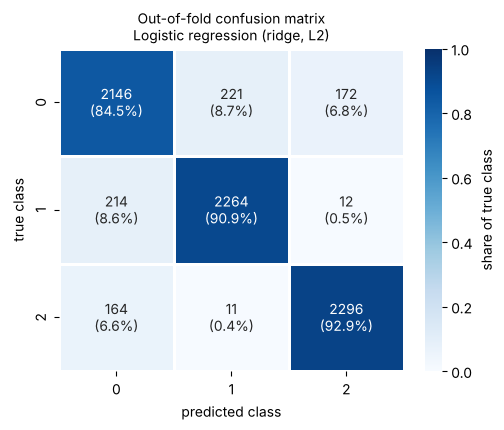

In [27]:
# ---------- 6e. Confusion matrix of the best model (out-of-fold predictions) ----------
best_est = clone(results[best_name]["search"].best_estimator_)
oof = cross_val_predict(best_est, X, y, cv=cv_splits[:N_SPLITS], n_jobs=-1)     # first repeat = a partition of the data
cm = confusion_matrix(y, oof)
cm_pct = cm / cm.sum(axis=1, keepdims=True)
annot = np.array([[f"{cm[i, j]}\n({cm_pct[i, j]:.1%})" for j in range(3)] for i in range(3)])
fig, ax = plt.subplots(figsize=(5.2, 4.4))
sns.heatmap(cm_pct, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, cbar_kws={"label": "share of true class"},
            linewidths=1, linecolor="white", ax=ax)
ax.set_xlabel("predicted class"); ax.set_ylabel("true class"); ax.grid(False)
ax.set_title(f"Out-of-fold confusion matrix\n{best_name}", fontsize=10)
plt.tight_layout(); plt.show()
print("Out-of-fold accuracy (one repeat):", round((oof == y).mean(), 4))
print("Per-class recall:", {c: round(cm_pct[c, c], 3) for c in range(3)})
off = [(i, j, cm[i, j]) for i in range(3) for j in range(3) if i != j]
print("Most frequent confusions (true -> predicted, count):", sorted(off, key=lambda t: -t[2])[:3])

### Discussion of the results

**One top tier, differences within noise.** Ridge logistic regression (0.8943), LDA on all features (0.8939), its L1-selected twin (identical, because the best L1 setting keeps all 20 features) and lasso logistic regression (0.8934) are separated by less than 0.001, while the fold-to-fold standard deviation is 0.007 to 0.008. The paired tests agree (corrected p between 0.57 and 0.79, and the "best" model wins in only 7 of 15 folds), so **these four models are statistically indistinguishable**. The CV rule picks ridge logistic regression as the final model, but picking LDA or lasso would be equally defensible; the choice among them is noise, not skill.

**Small but consistent gaps.** QDA (about 0.5 points lower) loses to the best model in 13 of 15 folds, but its p-value (0.018) does not survive the Bonferroni correction, so it is a borderline case. LDA on the forward-selected 10 features (also about 0.5 points lower) loses in all 15 folds and stays significant after correction: throwing away the correlated features costs a little accuracy.

**Clearly worse.** Naive Bayes with forward selection (about 2.4 points lower), the decision tree (3.2 points) and plain Naive Bayes (4.8 points) are far outside the noise (p < 0.001).

**Why the linear/Gaussian models win here (interpretation, not proven by these experiments).**
* LDA and logistic regression both build linear boundaries, and they converge to the same ~0.894 although their regularisation is very different. That suggests ~0.894 is close to what a linear boundary can reach on these features.
* QDA gives nothing extra over LDA, so letting each class have its own covariance is unnecessary: a shared covariance describes the data well. QDA only recovered from its default 0.8850 to 0.8895 with `reg_param=0.1`.
* The tree has to approximate oblique boundaries (combinations of correlated size and power features) with axis-parallel steps. The depth curve shows the usual picture: training accuracy keeps rising with depth, validation accuracy peaks at depth ~6 and then declines slightly.
* Naive Bayes is hurt most by the correlated features (within-class r up to about 0.93). Keeping only 6 forward-selected, less redundant features raised it from 0.847 to 0.871, which supports that explanation. It still stays 2 points below LDA, because the Gaussian shape assumption is also imperfect (clipped features).

**Feature selection did not improve accuracy for the linear models.** Lasso zeroes no feature at its best C (a stronger penalty that drops 4 features lowers accuracy to 0.8894; dropping 9 gives 0.8818), and the best L1 selector for LDA keeps all 20 features. Forward selection reaches about 0.889 with 10 features versus 0.894 with all 20. Selection is therefore useful for a simpler model, not for higher accuracy, except for Naive Bayes, where it helps.

**Where the errors are.** The best model reaches about 0.894 out-of-fold accuracy. Class 0 has the lowest recall (about 0.85, versus 0.91 and 0.93 for classes 1 and 2) and is confused with both other classes (0 and 1 are swapped about 220 times in each direction, and 0 is mistaken for 2 about 170 times). This is consistent with the class means in section 2: class 0 resembles class 1 in performance features (e.g. acceleration) and class 2 in body size.

**Reliability checks.** Re-scoring the tuned models on fresh folds changes the scores by at most 0.002, so the selection effect of tuning is small. The more important protection was removing the duplicate rows: on the raw data an unpruned tree scores about 0.897 (looking like the best model), but only 0.825 on unique rows. The expected test accuracy is about 0.89, assuming the test set resembles the training data (the test file contains no repeats of training rows, as the cleaned CV assumes).

## 7. Best model, final fit and submission

The final model is **chosen purely by CV score**: the model with the highest mean CV accuracy in the table above. It is then **refitted on all 7,500 unique training rows** (the whole pipeline, including scaling and any feature selection) and used once to predict the test set. The test set has no labels and was never used for tuning.

In [28]:
# ---------- 7. Choose by CV score, refit on all training data, predict test, write submission.csv ----------
final_name = summary.loc[0, "Model"]                              # highest mean CV accuracy
final_model = clone(results[final_name]["search"].best_estimator_)   # same pipeline + tuned hyper-parameters
final_model.fit(X, y)                                              # refit on ALL (unique) training rows
test_pred = final_model.predict(X_test)

submission = pd.DataFrame({ID: test[ID].values, TARGET: test_pred.astype(int)})[list(sample.columns)]
submission.to_csv("submission.csv", index=False)

# format checks against the sample submission
chk = pd.read_csv("submission.csv")
assert list(chk.columns) == list(sample.columns), "columns differ from the sample submission"
assert len(chk) == len(sample) and (chk[ID].values == sample[ID].values).all(), "ids differ from the sample submission"
assert chk[TARGET].isin([0, 1, 2]).all() and chk.notna().all().all()

print(f"Final model: {final_name}")
print(f"  tuned hyper-parameters: {results[final_name]['params']}")
print(f"  expected accuracy (CV): {results[final_name]['mean']:.4f} +/- {results[final_name]['std']:.4f}")
print(f"Saved submission.csv with shape {chk.shape} and columns {list(chk.columns)}")
display(pd.DataFrame({"share of training rows": y.value_counts(normalize=True).sort_index(),
                      "share of test predictions": chk[TARGET].value_counts(normalize=True).sort_index()}).round(3))
display(chk.head())

Final model: Logistic regression (ridge, L2)
  tuned hyper-parameters: {'clf__C': np.float64(0.1)}
  expected accuracy (CV): 0.8943 +/- 0.0077
Saved submission.csv with shape (2500, 2) and columns ['vehicle_id', 'vehicle_class']


,share of training rows,share of test predictions
vehicle_class,,
0,0.339,0.335
1,0.332,0.332
2,0.329,0.333


,vehicle_id,vehicle_class
0,10001,0
1,10002,0
2,10003,1
3,10004,2
4,10005,1


## 8. Viva notes

**Logistic regression (ridge / lasso).** It models the log-odds of each class as a linear function of the features (softmax for 3 classes) and is fitted by maximum likelihood plus a penalty: ridge shrinks all coefficients (`sum beta^2 / C`), lasso (`sum |beta| / C`) can set some exactly to zero. It assumes a linear log-odds and (roughly) independent observations; it makes no assumption about the feature distributions, and it needs standardised features for the penalty to be fair. *Here:* top tier (0.894). A linear boundary is enough, and ridge handles the strongly correlated features by sharing weight among them. Lasso zeroed no feature at its best C, because every feature adds a little signal; at smaller C it dropped features but accuracy fell.

**LDA.** Each class is a Gaussian with its own mean but a **shared covariance matrix**; Bayes' rule then gives linear boundaries. It assumes Gaussian classes with equal covariance. Shrinkage blends the estimated covariance with a diagonal one, which stabilises it when features are highly correlated. *Here:* top tier (0.894), almost the same as logistic regression, which is typical when the Gaussian assumption is roughly right. Shrinkage up to about 0.2 made no real difference with 7,500 rows, and too much shrinkage (0.5 and more) hurt. Subsets did not help: forward selection with 10 features lost 0.5 points, and the L1 selector kept all 20 features.

**QDA.** Like LDA, but **each class has its own covariance matrix**, so boundaries are quadratic. It is more flexible but has about 3x more covariance parameters (3 x 210), so it needs more data and regularisation (`reg_param`). *Here:* slightly below LDA (0.8895 vs 0.8939, borderline significant). Flexibility is not needed because shared-covariance LDA already fits well, and the clipped, non-Gaussian features make class-specific covariances noisier. It does better than default QDA (0.8850) once regularised.

**Decision tree.** It recursively makes axis-parallel splits that reduce impurity (gini or entropy) and predicts the majority class in each leaf. It has no distributional assumptions, needs no scaling and is easy to interpret, but it has high variance: an unpruned tree memorises the training data (training accuracy near 100%). *Here:* clearly worse than the linear models (0.863). The class boundaries are oblique combinations of correlated features, which axis-parallel splits approximate in a staircase fashion. Depth ~6 with light pruning was best, and deeper trees overfit. The top splits (battery capacity, wheelbase, acceleration) match the strongest features in the EDA. (The tree was also the model that benefited most from duplicate rows leaking across CV folds.)

**Gaussian Naive Bayes.** Bayes' rule with the naive assumption that features are **independent given the class**, each feature modelled by a 1-D Gaussian per class; it is simple, fast and needs little data. *Here:* the worst model (0.847), because the assumption is violated: many features are strongly correlated even within a class (r up to 0.93 for horsepower/torque), so the same evidence is counted several times and the decision becomes distorted. Forward selection of 6 less redundant features improved it by 2.4 points (0.871), supporting that explanation, and the Gaussian shape assumption is also only approximate (clipped features).

**Likely questions on the method.**
* *Why standardise inside a pipeline?* The scaler's mean and std must be learned from the training fold only; otherwise validation information leaks into training. Standardising also makes ridge/lasso penalties and LDA/QDA regularisation treat features equally.
* *Why the same folds for all models?* So scores are paired and comparable; we can then test the differences fold by fold.
* *Why were duplicates removed?* Identical rows in both training and validation folds let flexible models memorise; the tree's score dropped from 0.897 to 0.825 once they were removed, while LDA and QDA hardly changed.
* *Why is the best score slightly optimistic?* It is the maximum over a grid on the same folds; re-scoring on fresh folds shows the effect is at most about 0.002 here.
* *Which differences are significant?* The top four are tied; QDA is borderline; forward-selected LDA, Naive Bayes (with or without selection) and the tree are clearly worse.